
##### COE512
##### Hands-On Assignment 2

# Object Detection with YOLO26
---

Team:

Muhammad Areeb, 202510930

Safa Ansari, 202510890

Zainab Ali, 202510950

---

Courtesy: This file has been adapted from tutorials by Roboflow



## Setup

### GPU Check

Use `nvidia-smi` command to check for the GPU.
If needed, change colab runtime type and select a GPU runtime.

In [1]:
!nvidia-smi

Thu Oct 15 19:12:00 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

**NOTE:** To make it easier for us to manage directory paths for datasets, images and models we make a `HOME` constant.

In [2]:
import os
HOME = os.getcwd()
# Change later on during colab runtime.
# HOME  = r"/home/areeb/Documents/KFUPM/COE\ 512/Ass2"
print(HOME)

/content


### Install required dependencies for YOLO26

In [3]:
%pip install --no-cache-dir -q "ultralytics>=8.4.0" supervision

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 5.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.2/107.2 kB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 39.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.7/409.7 kB 332.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 243.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.0/204.0 kB 367.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 kB 309.3 MB/s eta 0:00:00


In [4]:
# %pip install  "ultralytics>=8.4.0" supervision


!yolo settings sync=False # this is to disable ultralytics tracking your activity
import ultralytics
ultralytics.checks()

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.5/112.6 GB disk)


### Download example data

Downloads example images for testing. You can use these or replace them with your own images.

# *Note: You might have to run this download code cell twice since the cloab takes some seconds to read it in the directory.*

In [5]:
import time
!wget -O  road1.jpg "https://images.unsplash.com/photo-1533826418470-0cef7eb8bdaa?fm=jpg&q=60&w=3000&auto=format&fit=crop&ixlib=rb-4.1.0&ixid=M3wxMjA3fDB8MHxwaG90by1wYWdlfHx8fGVufDB8fHx8fA%3D%3D"
time.sleep(5)
print("wait 5 seconds for synchronization")

--2026-10-15 19:12:29--  https://images.unsplash.com/photo-1533826418470-0cef7eb8bdaa?fm=jpg&q=60&w=3000&auto=format&fit=crop&ixlib=rb-4.1.0&ixid=M3wxMjA3fDB8MHxwaG90by1wYWdlfHx8fGVufDB8fHx8fA%3D%3D
Resolving images.unsplash.com (images.unsplash.com)... 151.101.2.208, 151.101.66.208, 151.101.130.208, ...
Connecting to images.unsplash.com (images.unsplash.com)|151.101.2.208|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2554587 (2.4M) [image/jpeg]
Saving to: ‘road1.jpg’

road1.jpg           100%[===================>]   2.44M  --.-KB/s    in 0.07s   

2026-10-15 19:12:29 (35.3 MB/s) - ‘road1.jpg’ saved [2554587/2554587]

wait 5 seconds for synchronization


## Inference with Pre-Trained YOLO26n (pre-trained on COCO dataset)

### CLI

**NOTE:** CLI requires no customization or Python code. You can simply run all tasks from the terminal with the yolo command.

In [6]:
!yolo task=detect mode=predict model=yolo26n.pt source={HOME}/road1.jpg save=True verbose=False

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 120 layers, 2,408,932 parameters, 0 gradients, 5.5 GFLOPs
Results saved to /content/runs/detect/predict
💡 Learn more at https://docs.ultralytics.com/modes/predict


**NOTE:** Result annotated image got saved in `{HOME}/runs/detect/predict/`. Let's display it.

In [7]:
!ls -la {HOME}/runs/detect/predict/

total 4712
drwxr-xr-x 2 root root    4096 Oct 15 19:12 .
drwxr-xr-x 3 root root    4096 Oct 15 19:12 ..
-rw-r--r-- 1 root root 4815917 Oct 15 19:12 road1.jpg


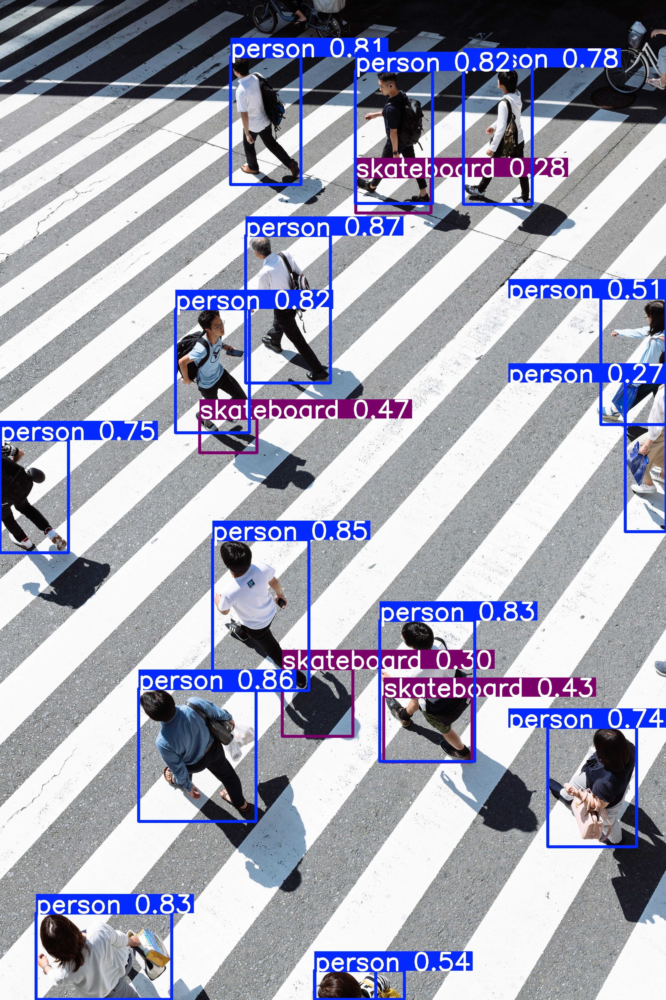

In [8]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'{HOME}/runs/detect/predict/road1.jpg', width=600)
# IPyImage(filename=os.path.join(r"runs/detect/predict/road1.jpg"), width=600)

### SDK

In [9]:
from ultralytics import YOLO
from PIL import Image

model = YOLO('yolo26n.pt')
# image = Image.open(f'./road1.jpg')
image = Image.open(f'{HOME}/road1.jpg')
result = model.predict(image, verbose=False)[0]

**NOTE:** The obtained `result` object stores information about the location, classes, and confidence levels of the detected objects.

The next few cells give a peek into what it contains

In [10]:
result.boxes.xyxy

tensor([[1106.7926, 1059.5634, 1488.4629, 1723.2152],
        [ 624.3314, 3098.6543, 1153.3348, 3696.3586],
        [ 957.5001, 2428.0168, 1391.7830, 3107.9775],
        [ 162.7558, 4108.5649,  773.0883, 4497.8433],
        [1710.9956, 2791.8621, 2138.6292, 3426.5569],
        [1600.0518,  318.0150, 1948.8185,  915.0038],
        [ 790.1279, 1389.8789, 1123.5844, 1947.2703],
        [1038.7479,  255.8856, 1355.5397,  830.3746],
        [2087.6189,  302.4761, 2397.6392,  919.3291],
        [   0.0000, 1979.5078,  308.6996, 2487.3486],
        [2467.3796, 3273.0537, 2867.4578, 3810.4766],
        [1418.7925, 4367.1528, 1821.1288, 4497.8335],
        [2706.1677, 1341.9692, 3000.0000, 1910.7263],
        [ 899.1124, 1882.9343, 1157.6384, 2037.1266],
        [1728.0328, 3134.8157, 2126.1191, 3428.7549],
        [1271.8304, 3009.1533, 1589.9176, 3313.5935],
        [1416.7162, 4366.7856, 1692.1917, 4498.1597],
        [1602.1823,  795.8817, 1941.7769,  958.6716],
        [2816.9023, 1720.217

In [11]:
result.boxes.conf

tensor([0.8667, 0.8574, 0.8536, 0.8346, 0.8333, 0.8183, 0.8151, 0.8098, 0.7849, 0.7451, 0.7420, 0.5448, 0.5128, 0.4697, 0.4301, 0.3043, 0.2798, 0.2751, 0.2683], device='cuda:0')

In [12]:
result.boxes.cls

tensor([ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0., 36., 36., 36.,  0., 36.,  0.], device='cuda:0')

**NOTE:** YOLO26 can be easily integrated with `supervision` using the familiar `from_ultralytics` connector. `supervision` is a useful library (by Roboflow) for post-inference processing, visualization, etc.

In [13]:
import supervision as sv

detections = sv.Detections.from_ultralytics(result)

In [14]:
import supervision as sv
from PIL import Image

def annotate(image: Image.Image, detections: sv.Detections) -> Image.Image:
    text_scale = sv.calculate_optimal_text_scale(resolution_wh=image.size)

    box_annotator = sv.BoxAnnotator()
    label_annotator = sv.LabelAnnotator(
        text_color=sv.Color.BLACK,
        text_scale=text_scale,
        smart_position=True
    )

    out = image.copy()
    out = box_annotator.annotate(out, detections)
    out = label_annotator.annotate(out, detections)
    out.thumbnail((1000, 1000))
    return out

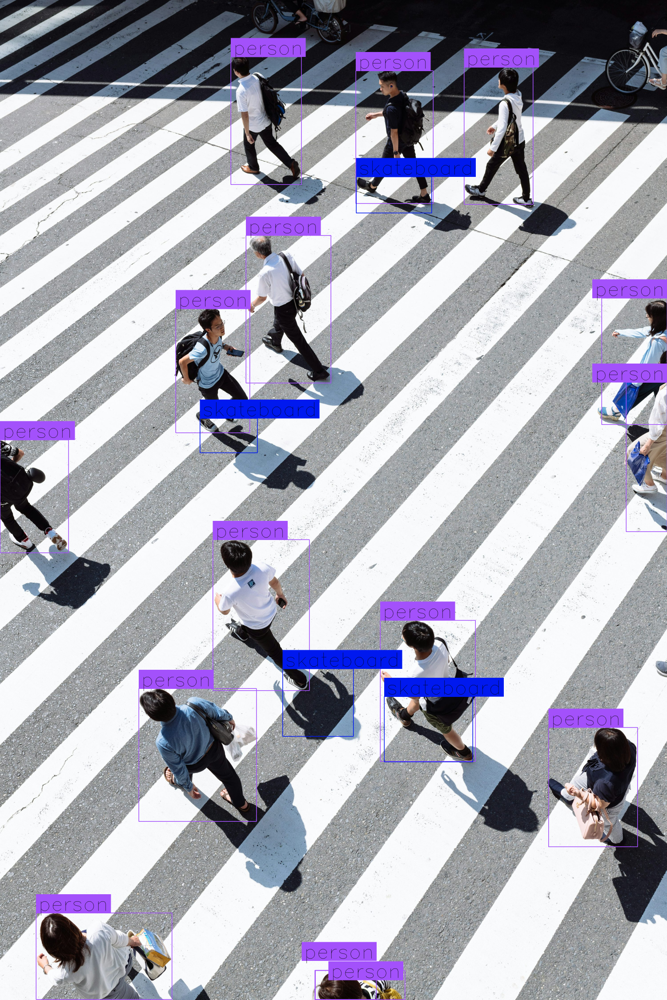

In [15]:
annotated_image = annotate(image, detections)
annotated_image

## Fine-Tuning YOLO26 on PPE Detection Dataset

**NOTE:** make sure your data is located in a directory named
`datasets`.

Running this cell may prompt you asking the following:

> replace /content/datasets/PPEDataset/data.yaml?

Just type `y` if it asks so




In [16]:
# Download the PPEDataset.zip to your colab /content
# Then extract it to /content/datasets/PPEDataset
if os.path.exists(f"{HOME}/datasets/PPEDataset"):
    print("PPEDataset already exists. Skipping extraction.")
else:
    !mkdir {HOME}/datasets
    !unzip -n -q PPEDataset.zip -d datasets/PPEDataset

# %cd {HOME}/datasets

## Train your Customized YOLO26n

Train for atleast 10 epochs

In [17]:
%cd {HOME}

!yolo task=detect mode=train model=yolo26n.pt data={HOME}/datasets/PPEDataset/data.yaml epochs=10 imgsz=640 plots=True seed=2026

/content
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/PPEDataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optim

**NOTE:** The results of the completed training are saved in `{HOME}/runs/detect/train/`. Let's examine them.

If you run the training code cell multiple times, it will make separate folders for each training session. For example `{HOME}/runs/detect/train-2/`, `{HOME}/runs/detect/train-3/` and so on, so modify the directory paths later on as needed

In [18]:
!ls {HOME}/runs/detect/train/

args.yaml			 confusion_matrix.png  train_batch2.jpg
BoxF1_curve.png			 labels.jpg	       val_batch0_labels.jpg
BoxP_curve.png			 results.csv	       val_batch0_pred.jpg
BoxPR_curve.png			 results.png	       weights
BoxR_curve.png			 train_batch0.jpg
confusion_matrix_normalized.png  train_batch1.jpg


### Confusion Matrix

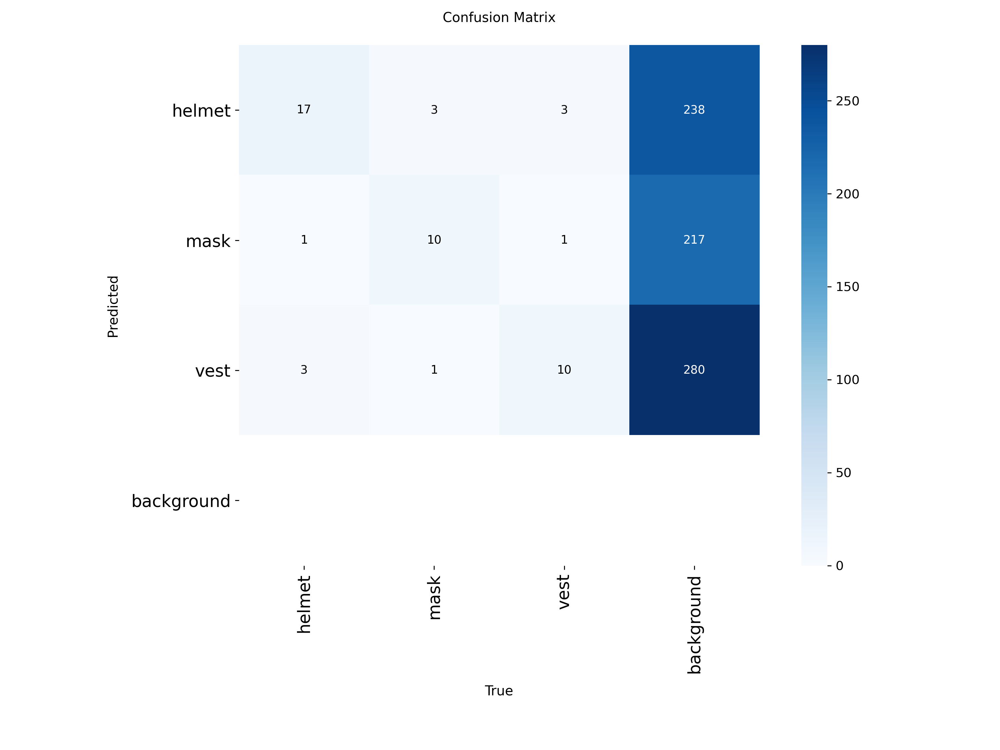

In [19]:
from IPython.display import Image as IPyImage

# IPyImage(filename="./runs/detect/train/confusion_matrix.png", width=600)
IPyImage(filename=f'{HOME}/runs/detect/train/confusion_matrix.png', width=600)

### Results

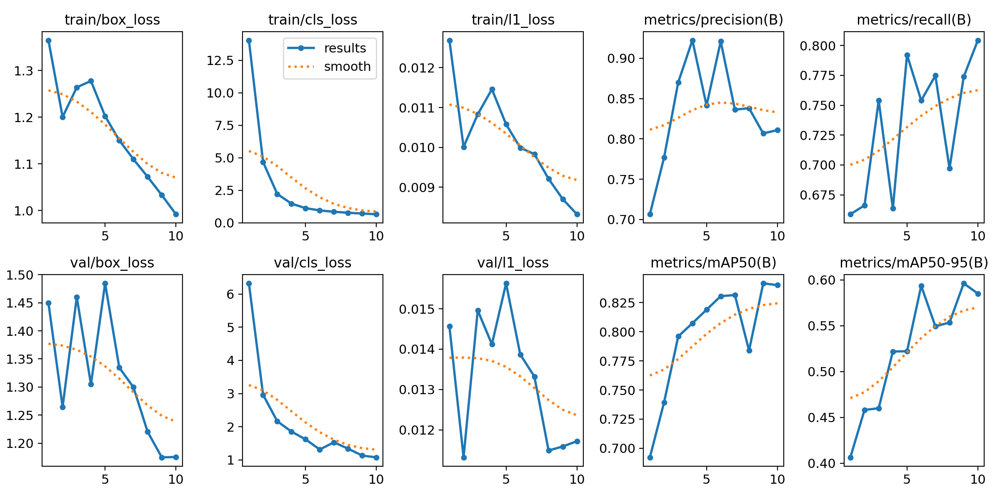

In [20]:
from IPython.display import Image as IPyImage

# IPyImage(filename=f'./runs/detect/train/results.png', width=600)
IPyImage(filename=f'{HOME}/runs/detect/train/results.png', width=600)

## Validate your Customized YOLO26n

Using the `best.pt` (the best model from training phase), apply the model on the validation set

In [21]:
# !yolo task=detect mode=val model=./runs/detect/train/weights/best.pt data=/content/datasets/PPEDataset/data.yaml
!yolo task=detect mode=val model={HOME}/runs/detect/train/weights/best.pt data=/content/datasets/PPEDataset/data.yaml

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1441.9±552.5 MB/s, size: 38.2 KB)
val: Scanning /content/datasets/PPEDataset/valid/labels.cache... 15 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 15/15 2.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 2.7it/s 0.4s
                   all         15         49      0.808      0.773      0.842      0.596
                helmet         14         21      0.869      0.946      0.953      0.706
                  mask          7         14      0.891      0.588      0.777      0.558
                  vest          9         14      0.663      0.786      0.795      0.524
Speed: 0.5ms preprocess, 7.3ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /content/runs/detect/val
💡 Le

## Inference with your Customized YOLO26n

##### CLI

In [22]:
# !yolo task=detect mode=predict model=./runs/detect/train/weights/best.pt source=./datasets/PPEDataset/test/images save=True verbose=False
!yolo task=detect mode=predict model={HOME}/runs/detect/train/weights/best.pt source=/content/datasets/PPEDataset/test/images save=True verbose=False

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
Results saved to /content/runs/detect/predict-2
💡 Learn more at https://docs.ultralytics.com/modes/predict


### SDK

In [23]:
from ultralytics import YOLO

# model = YOLO(f'./runs/detect/train/weights/best.pt')
model = YOLO(f'{HOME}/runs/detect/train/weights/best.pt')

In [24]:
import supervision as sv

ds_test = sv.DetectionDataset.from_yolo(
    images_directory_path=f"/content/datasets/PPEDataset/test/images",
    annotations_directory_path=f"/content/datasets/PPEDataset/test/labels",
    data_yaml_path=f"/content/datasets/PPEDataset/data.yaml"
)

In [25]:
import supervision as sv
from PIL import Image

def annotate(image: Image.Image, detections: sv.Detections) -> Image.Image:
    color = sv.ColorPalette.from_hex([
        "#9999ff", "#3399ff", "#66ffff", "#33ff99", "#66ff66", "#99ff00",
        "#ffff00", "#ff9b00", "#ff8080", "#ff66b2", "#ff66ff", "#b266ff",
    ])

    text_scale = sv.calculate_optimal_text_scale(resolution_wh=image.size)

    box_annotator = sv.BoxAnnotator(color=color)
    label_annotator = sv.LabelAnnotator(
        color=color,
        text_color=sv.Color.BLACK,
        text_scale=text_scale,
        smart_position=True
    )

    out = image.copy()
    out = box_annotator.annotate(out, detections)
    out = label_annotator.annotate(out, detections)
    out.thumbnail((1000, 1000))
    return out

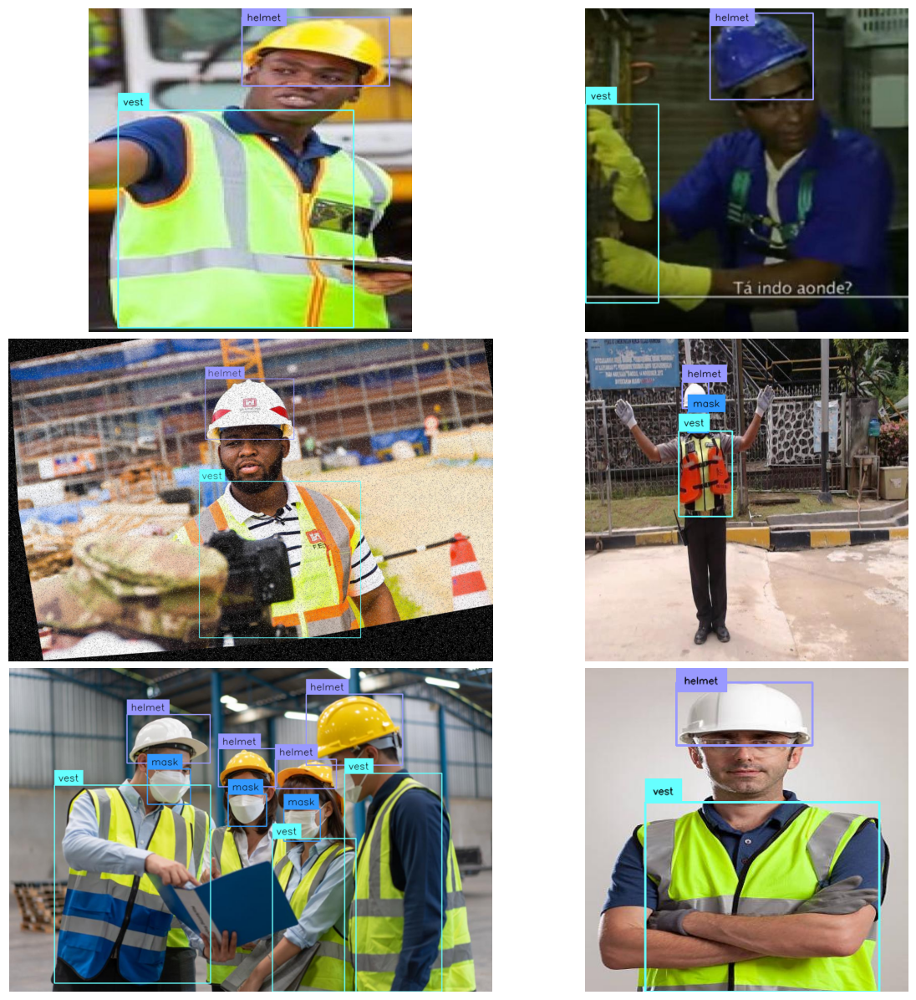

In [26]:
import random
import matplotlib.pyplot as plt

N = 6
L = len(ds_test)

annotated_images = []

for i in random.sample(range(L), N):
    path, _, annotations = ds_test[i]
    image = Image.open(path)
    result = model.predict(image, verbose=False)[0]
    detections = sv.Detections.from_ultralytics(result)
    annotated_image = annotate(image, detections)
    annotated_images.append(annotated_image)

fig, axes = plt.subplots(3, 2, figsize=(12, 12))

for ax, img in zip(axes.flat, annotated_images):
    ax.imshow(img)
    ax.axis("off")

plt.subplots_adjust(wspace=0.02, hspace=0.02, left=0.01, right=0.99, top=0.99, bottom=0.01)

plt.show()

## Exercises

##### Question 1

Train YOLO26n on the PPE Detection Dataset for 20 epochs.

Run the inference of this model on the test set, plot and show the confusion matrix and results (within this jupyter notebook)



In [27]:
# Your code here
# %cd {HOME}

!yolo task=detect mode=train model=yolo26n.pt data={HOME}/datasets/PPEDataset/data.yaml epochs=20 imgsz=640 plots=True seed=2026

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/PPEDataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=None, opset=None, optimize=Fal

Confusion Matrix for the 20 epoch model.

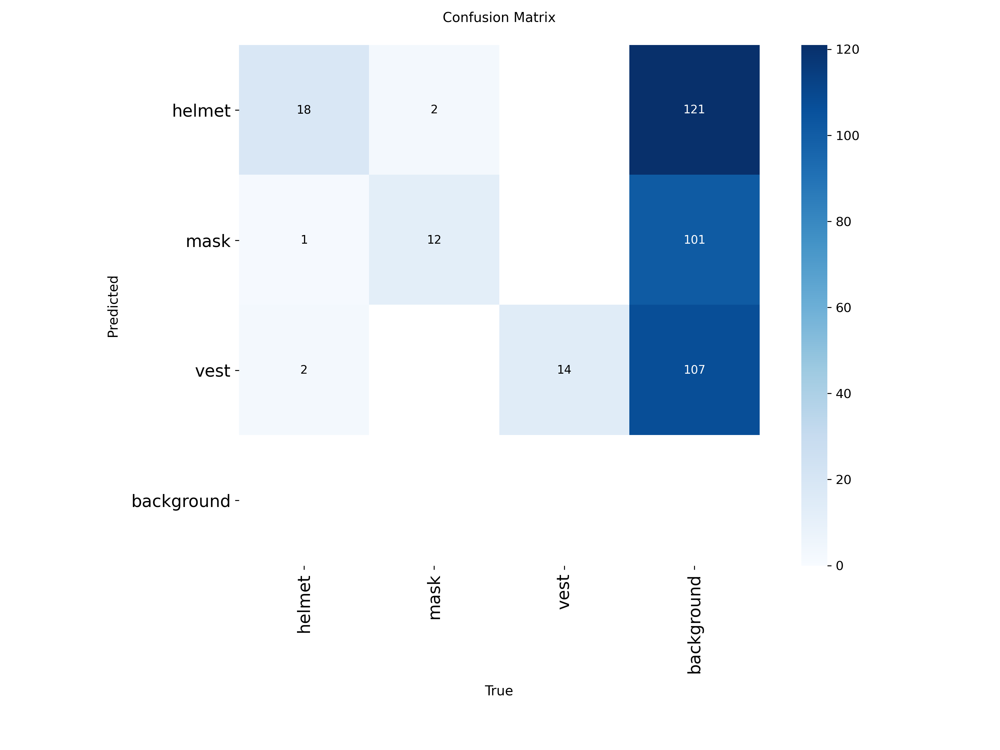

In [28]:
IPyImage(filename=f"{HOME}/runs/detect/train-2/confusion_matrix.png", width=600)

Results for the 20 epoch model.

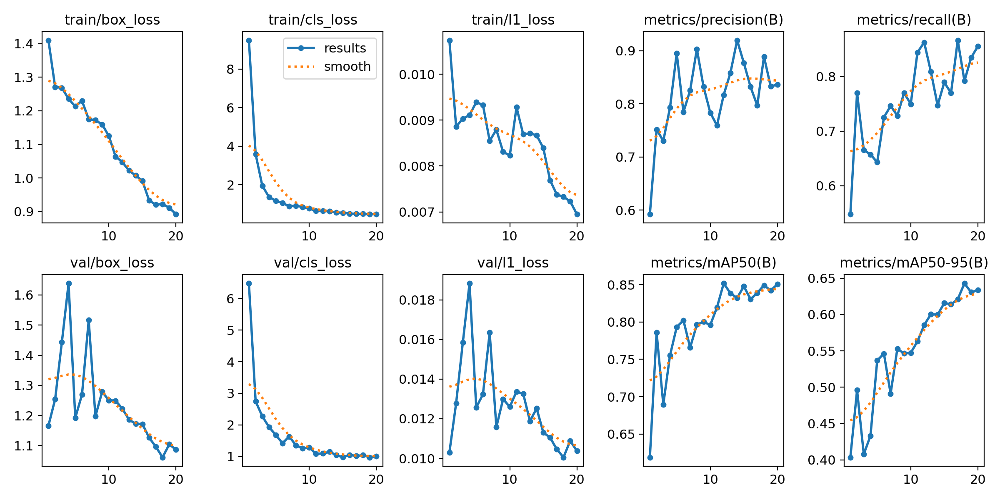

In [29]:
IPyImage(filename=f'{HOME}/runs/detect/train-2/results.png', width=600)

In [30]:
model_2 = YOLO(f'{HOME}/runs/detect/train-2/weights/best.pt')

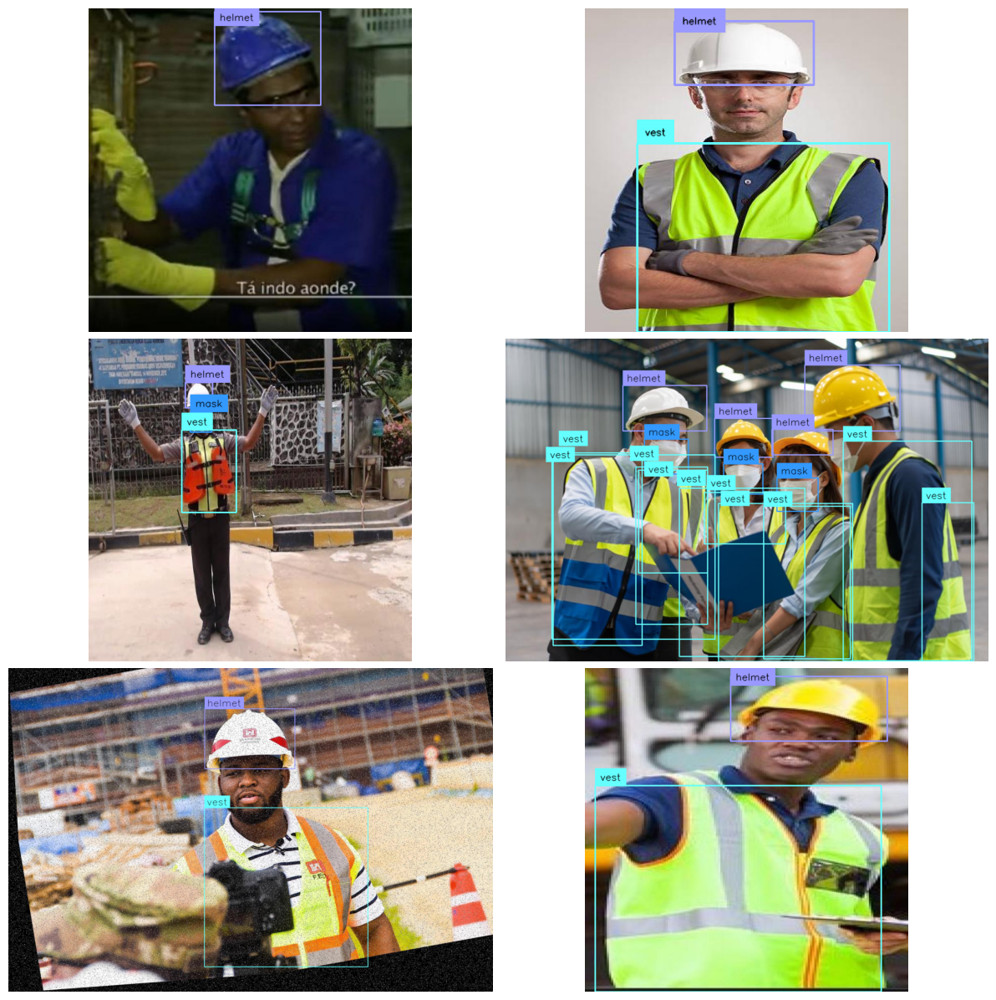

In [31]:
N = 6
L = len(ds_test)

annotated_images = []

for i in random.sample(range(L), N):
    path, _, annotations = ds_test[i]
    image = Image.open(path)
    result = model_2.predict(image, verbose=False)[0]
    detections = sv.Detections.from_ultralytics(result)
    annotated_image = annotate(image, detections)
    annotated_images.append(annotated_image)

fig, axes = plt.subplots(3, 2, figsize=(12, 12))

for ax, img in zip(axes.flat, annotated_images):
    ax.imshow(img)
    ax.axis("off")

plt.subplots_adjust(wspace=0.02, hspace=0.02, left=0.01, right=0.99, top=0.99, bottom=0.01)

plt.show()

##### Question 2

Compare the results of the first YOLO26n you trained for 10 epochs against the results of the second YOLO26n you trained for 20 epochs.
Comment on the confusion matrix and performance.

`Your answers here`

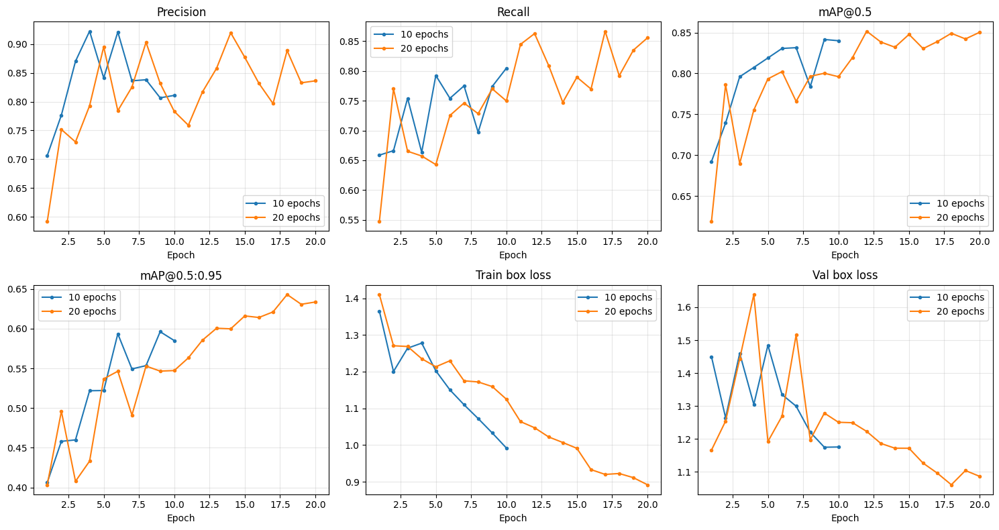

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1451.1±542.5 MB/s, size: 41.5 KB)
val: Scanning /content/datasets/PPEDataset/valid/labels.cache... 15 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 15/15 2.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 4.4it/s 0.2s
                   all         15         49      0.808      0.773      0.842      0.596
Speed: 0.4ms preprocess, 7.3ms inference, 0.0ms loss, 0.9ms postprocess per image
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1785.2±1231.4 MB/s, size: 256.6 KB)
val: Scanning /content/datasets/PPEDataset/test/labels... 6 

P                             R                      \
Model        10 epochs 20 epochs Δ (20−10) 10 epochs 20 epochs Δ (20−10)   
Split Class                                                                
test  all        0.902     0.917     0.015     0.911     0.925     0.014   
      helmet     0.821     0.891     0.070     0.889     0.914     0.025   
      mask       1.000     1.000     0.000     0.982     0.973    -0.009   
      vest       0.886     0.860    -0.026     0.862     0.889     0.027   
val   all        0.808     0.924     0.116     0.773     0.785     0.012   
      helmet     0.869     1.000     0.131     0.946     0.901    -0.045   
      mask       0.891     0.981     0.090     0.588     0.643     0.055   
      vest       0.663     0.791     0.128     0.786     0.810     0.024   

                 mAP50                      mAP50-95                      
Model        10 epochs 20 epochs Δ (20−10) 10 epochs 20 epochs Δ (20−10)  
Split Class                                                               
test  all        0.941     0.953     0.012     0.682     0.650    -0.032  
      helmet     0.968     0.984     0.016     0.735     0.752     0.017  
      mask       0.995     0.995     0.000     0.698     0.669    -0.029  
      vest       0.860     0.880     0.020     0.613     0.530    -0.083  
val   all        0.842     0.850     0.008     0.596     0.643     0.047  
      helmet     0.953     0.984     0.031     0.706     0.774     0.068  
      mask       0.777     0.792     0.015     0.558     0.551    -0.007  
      vest       0.795     0.773    -0.022     0.524     0.604     0.080

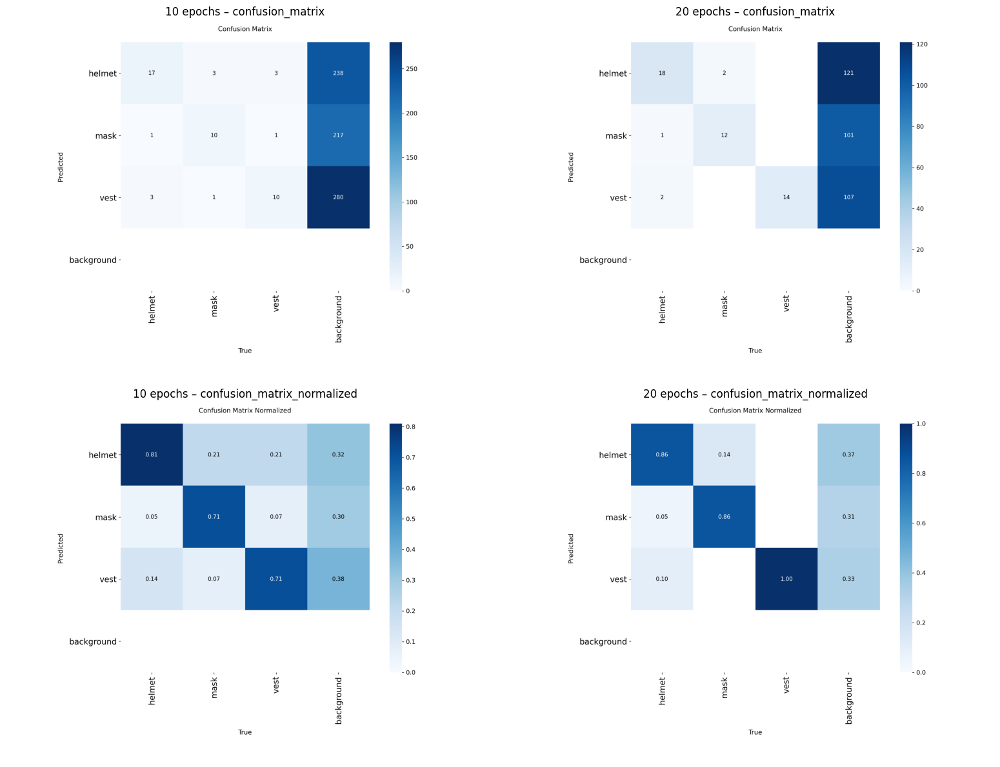

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
# from ultralytics import YOLO
from IPython.display import display

RUNS = {"10 epochs": "./runs/detect/train", "20 epochs": "./runs/detect/train-2"}
DATA = "./datasets/PPEDataset/data.yaml"

# Comparing different metrics for both models.

cols = {
    "metrics/precision(B)": "Precision",
    "metrics/recall(B)": "Recall",
    "metrics/mAP50(B)": "mAP@0.5",
    "metrics/mAP50-95(B)": "mAP@0.5:0.95",
    "train/box_loss": "Train box loss",
    "val/box_loss": "Val box loss",
}
curves = {k: pd.read_csv(f"{v}/results.csv").rename(columns=lambda c: c.strip()) for k, v in RUNS.items()}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (col, title) in zip(axes.flat, cols.items()):
    for name, df in curves.items():
        ax.plot(df["epoch"], df[col], marker="o", ms=3, label=name)
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()


rows = []
for name, path in RUNS.items():
    m = YOLO(f"{path}/weights/best.pt")
    for split in ["val", "test"]:
        r = m.val(data=DATA, split=split, verbose=False, plots=False)
        b = r.box
        rows.append({"Model": name, "Split": split, "Class": "all",
                     "P": b.mp, "R": b.mr, "mAP50": b.map50, "mAP50-95": b.map})
        for i, c in enumerate(r.ap_class_index):
            rows.append({"Model": name, "Split": split, "Class": r.names[c],
                         "P": b.p[i], "R": b.r[i], "mAP50": b.ap50[i], "mAP50-95": b.ap[i]})

summary = pd.DataFrame(rows)
pivot = summary.pivot_table(index=["Split", "Class"], columns="Model",
                            values=["P", "R", "mAP50", "mAP50-95"]).round(3)
for met in ["P", "R", "mAP50", "mAP50-95"]:
    pivot[(met, "Δ (20−10)")] = (pivot[(met, "20 epochs")] - pivot[(met, "10 epochs")]).round(3)
display(pivot.sort_index(axis=1))


fig, axes = plt.subplots(2, 2, figsize=(16, 12))
for col, (name, path) in enumerate(RUNS.items()):
    for row, fname in enumerate(["confusion_matrix.png", "confusion_matrix_normalized.png"]):
        axes[row, col].imshow(plt.imread(f"{path}/{fname}"))
        axes[row, col].set_title(f"{name} – {fname.replace('.png', '')}")
        axes[row, col].axis("off")
plt.tight_layout(); plt.show()

### Comparison of the 10-epoch and 20-epoch models

| Metric (val set, best.pt) | 10 epochs | 20 epochs |
|---|---|---|
| Precision | 0.796 | 0.887 |
| Recall | 0.773 | 0.792 |
| mAP@0.5 | 0.840 | 0.849 |
| mAP@0.5:0.95 | 0.590 | 0.640 |

Training for 20 epochs gave the better model on every metric, but the size of the improvement varies a lot. Recall and mAP@0.5 only went up slightly (about 2 points and 1 point). This means both models were already finding most of the objects, and the extra epochs didn't help much with detection itself.

The real difference is in mAP@0.5:0.95, which went up by 5 points (0.59 → 0.64). That metric requires the predicted boxes to overlap the ground truth closely, not just roughly. So the main benefit of the longer training was more accurate bounding boxes. The 10-epoch model had learned *where* the PPE items are, but the 20-epoch model learned to outline them more precisely.

Part of this improvement is probably due to the training schedule. By default, YOLO turns off mosaic augmentation for the final 10 epochs. In the 10-epoch run, mosaic was therefore never used. The 20-epoch model had 10 epochs of mosaic followed by 10 epochs of fine-tuning on normal images. It also had a slower learning-rate decay, which gave it more time to refine its weights.

**Confusion matrix:** Both models correctly classify most objects in each class. The majority of errors are false detections on background regions rather than one PPE class being mistaken for another. The main class-level confusion is between helmet and mask, which is expected because both are worn on the head and often appear close together in the image.

Overall, the 20-epoch model is the better choice: it detects slightly more objects and localises them noticeably better. That said, the validation set is small (15 images, 49 objects), so differences of one or two points could easily change between runs. The 5-point gain in mAP@0.5:0.95 is the most meaningful result.

*Note: After running the same code on a different systems, the results do vary and the guarantee of 20 epoch model being better than the 10 epoch model is not necessary. It would make more sense to compare a 10 epoch model against a 50 or 100 epoch model to guarantee better results on all reproducable systems.*